# FarmTech Solutions | Fase 6: Visão Computacional com YOLOv5
**Detecção de bananas e cadernos**

**Aluno(a):** _(Natalia Faro - RM 568610)_

## 1. Objetivo
A FarmTech Solutions está expandindo seus serviços de IA para além do agronegócio, incluindo visão computacional. Este notebook demonstra, na prática, como um modelo **YOLOv5** é treinado, validado e testado para detectar dois objetos bem diferentes entre si:

| Classe | Índice | Descrição |
|---|---|---|
| `banana` | 0 | bananas verdes, maduras, descascadas, em penca ou isoladas |
| `caderno` | 1 | cadernos fechados, abertos, de espiral, de várias cores |

## 2. Dataset
- **80 imagens** no total: 40 de banana + 40 de caderno (mistura de fotos próprias e do Unsplash).
- Divisão por classe: **32 treino / 4 validação / 4 teste**.
- Rotulação feita no **Make Sense AI**, exportada em formato YOLO.
- Critérios de rotulação: uma caixa por caderno visível; pencas/cachos grandes com uma caixa só na penca inteira; banana descascada conta como `banana`.

## 3. Plano do experimento
Dois treinos idênticos, mudando **apenas o número de épocas (30 e 60)**, para comparar acurácia, erro e desempenho.

## Etapa 1: Conectar ao Google Drive e preparar o dataset
O dataset está no Drive. Para o treino ficar mais rápido, copiamos a pasta para o disco local do Colab (ler direto do Drive é lento).

> **Antes de rodar:** ative a GPU em *Ambiente de execução → Alterar tipo de ambiente de execução → GPU (T4)*.

In [28]:
# Monta o Google Drive no Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
import os, shutil

# Caminho da pasta do dataset no Drive (ajuste se necessário)
DRIVE_DATASET = '/content/drive/MyDrive/FarmTech_YOLO'
# Cópia local (mais rápida para o treino)
LOCAL_DATASET = '/content/FarmTech_YOLO'

# Remove cópia anterior (se existir) e copia do Drive para o disco local
if os.path.exists(LOCAL_DATASET):
    shutil.rmtree(LOCAL_DATASET)
shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)
print('Dataset copiado para', LOCAL_DATASET)

Dataset copiado para /content/FarmTech_YOLO


### Verificação do dataset
Conferimos se cada pasta tem a quantidade esperada e se **toda imagem tem um rótulo `.txt` com o mesmo nome**. Imagem sem rótulo seria interpretada pelo YOLO como "sem objeto", o que prejudicaria o treino.

In [30]:
# Contagem esperada por etapa (imagens)
esperado = {'train': 64, 'val': 8, 'test': 8}

for etapa, qtd in esperado.items():
    imgs = sorted(f for f in os.listdir(f'{LOCAL_DATASET}/images/{etapa}')
                  if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    lbls = {f for f in os.listdir(f'{LOCAL_DATASET}/labels/{etapa}') if f.endswith('.txt')}
    # Imagens sem rótulo correspondente
    sem_rotulo = [i for i in imgs if os.path.splitext(i)[0] + '.txt' not in lbls]
    print(f'{etapa:5s} | imagens: {len(imgs):2d} (esperado {qtd}) | rótulos: {len(lbls):2d} | sem rótulo: {sem_rotulo}')

train | imagens: 64 (esperado 64) | rótulos: 64 | sem rótulo: []
val   | imagens:  8 (esperado 8) | rótulos:  8 | sem rótulo: []
test  | imagens:  8 (esperado 8) | rótulos:  8 | sem rótulo: []


## Etapa 2: Instalar o YOLOv5
Clonamos o repositório oficial da Ultralytics e instalamos as dependências.

In [31]:
# Clona o YOLOv5 e instala as dependências
!git clone https://github.com/ultralytics/yolov5 /content/yolov5
%cd /content/yolov5
!pip install -q -r requirements.txt

fatal: destination path '/content/yolov5' already exists and is not an empty directory.
/content/yolov5


In [32]:
import torch
# Confirma se a GPU está ativa (o treino em CPU seria muito lento)
print('PyTorch:', torch.__version__)
print('GPU disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Placa:', torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU disponível: True
Placa: Tesla T4


## Etapa 3: Configurar o `data.yaml`
Arquivo que informa ao YOLO onde estão as imagens e quais são as classes. A **ordem das classes** precisa ser a mesma usada no Make Sense (`banana` = 0, `caderno` = 1).

In [33]:
# Cria o arquivo de configuração do dataset
yaml_texto = """path: /content/FarmTech_YOLO
train: images/train
val: images/val
test: images/test

nc: 2
names: ['banana', 'caderno']
"""
DATA_YAML = '/content/data_farmtech.yaml'
with open(DATA_YAML, 'w') as f:
    f.write(yaml_texto)
print(open(DATA_YAML).read())

path: /content/FarmTech_YOLO
train: images/train
val: images/val
test: images/test

nc: 2
names: ['banana', 'caderno']



## Etapa 4: Treinamento
Usamos o **YOLOv5s** (modelo pequeno) com pesos pré-treinados no COCO (*transfer learning*). Como temos só 64 imagens de treino, partir de pesos pré-treinados é essencial.

Parâmetros fixos nos dois treinos: imagem 640 px, batch 16, pesos `yolov5s.pt`. **Só as épocas mudam.**

### Simulação A: 30 épocas

In [34]:
import time

# Treino com 30 épocas; medimos o tempo total
t0 = time.time()
!python train.py --img 640 --batch 16 --epochs 30 --data {DATA_YAML} --weights yolov5s.pt --name banana_caderno_30ep --cache
tempo_30 = time.time() - t0
print(f'\nTempo de treino (30 épocas): {tempo_30/60:.1f} min')

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791828388.425614    8813 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/data_farmtech.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs

### Simulação B: 60 épocas

In [35]:
# Treino com 60 épocas (todo o resto igual); medimos o tempo total
t0 = time.time()
!python train.py --img 640 --batch 16 --epochs 60 --data {DATA_YAML} --weights yolov5s.pt --name banana_caderno_60ep --cache
tempo_60 = time.time() - t0
print(f'\nTempo de treino (60 épocas): {tempo_60/60:.1f} min')

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791828534.085673    9548 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/data_farmtech.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs

## Etapa 5: Validação e Teste
Usamos o `val.py` com o melhor peso de cada treino (`best.pt`):
- **Validação** (8 imagens): as mesmas usadas durante o treino para acompanhar o desempenho.
- **Teste** (8 imagens): nunca vistas pelo modelo, e por isso a medida mais honesta de generalização.

Métricas:
- **Precisão (P):** das detecções feitas, quantas estavam certas.
- **Recall (R):** dos objetos que existiam, quantos foram encontrados.
- **mAP@0.5:** qualidade geral da detecção com tolerância de 50% de sobreposição.
- **mAP@0.5:0.95:** versão mais rigorosa, com média de várias tolerâncias.

In [36]:
import re

resultados = {}  # guarda as métricas de cada experimento

def avaliar(epocas, etapa):
    """Roda val.py em 'val' ou 'test' e extrai a linha 'all' com as métricas."""
    nome = f'banana_caderno_{epocas}ep'
    saida = !python val.py --weights runs/train/{nome}/weights/best.pt --data {DATA_YAML} --img 640 --task {etapa} --name {etapa}_{epocas}ep
    # Procura a linha com as métricas gerais (classe "all")
    for linha in saida:
        partes = linha.split()
        if len(partes) >= 7 and partes[0] == 'all':
            p, r, m50, m5095 = map(float, partes[-4:])
            resultados[(epocas, etapa)] = {'Precisão': p, 'Recall': r, 'mAP@0.5': m50, 'mAP@0.5:0.95': m5095}
    print('\n'.join(saida[-12:]))  # mostra o final da saída (tabela por classe)

for ep in (30, 60):
    for etapa in ('val', 'test'):
        print(f'\n===== {ep} épocas | {etapa} =====')
        avaliar(ep, etapa)


===== 30 épocas | val =====
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/FarmTech_YOLO/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt

                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 5.9s/it 5.9s
                   all          8          8          1      0.869      0.995      0.661
                banana          8          4          1      0.977      0.995      0.795
               caderno          8          4          1      0.761      0.995      0.526
Speed: 0.3ms pre-process, 15.6ms inference, 10.0ms NMS per image at shape (32, 3, 640, 640)
Results saved to runs/val/val_30ep2

===== 30 épocas | test =====
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs

test: Scanning /content/FarmTech_YOLO/labels/test... 8

## Etapa 6: Detecção nas imagens de teste
Rodamos o `detect.py` com os dois modelos nas 8 imagens de teste. Os resultados ficam em `runs/detect/`.

In [37]:
# Detecção com o modelo de 30 épocas
!python detect.py --weights runs/train/banana_caderno_30ep/weights/best.pt --source {LOCAL_DATASET}/images/test --img 640 --conf 0.25 --line-thickness 5 --exist-ok --name detect_30ep

detect: weights=['runs/train/banana_caderno_30ep/weights/best.pt'], source=/content/FarmTech_YOLO/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=detect_30ep, exist_ok=True, line_thickness=5, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/FarmTech_YOLO/images/test/banana_test_01.jpg: 448x640 1 banana, 29.6ms
image 2/8 /content/FarmTech_YOLO/images/test/banana_test_02.jpeg: 640x384 1 banana, 30.1ms
image 3/8 /content/FarmTech_YOLO/images/test/banana_test_03.jpg: 640x480 1 banana, 28.8ms
image 4/8 /content/F

In [38]:
# Detecção com o modelo de 60 épocas
!python detect.py --weights runs/train/banana_caderno_60ep/weights/best.pt --source {LOCAL_DATASET}/images/test --img 640 --conf 0.25 --line-thickness 5 --exist-ok --name detect_60ep

detect: weights=['runs/train/banana_caderno_60ep/weights/best.pt'], source=/content/FarmTech_YOLO/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=detect_60ep, exist_ok=True, line_thickness=5, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/FarmTech_YOLO/images/test/banana_test_01.jpg: 448x640 1 banana, 38.8ms
image 2/8 /content/FarmTech_YOLO/images/test/banana_test_02.jpeg: 640x384 1 banana, 40.4ms
image 3/8 /content/FarmTech_YOLO/images/test/banana_test_03.jpg: 640x480 1 banana, 39.8ms
image 4/8 /content/F

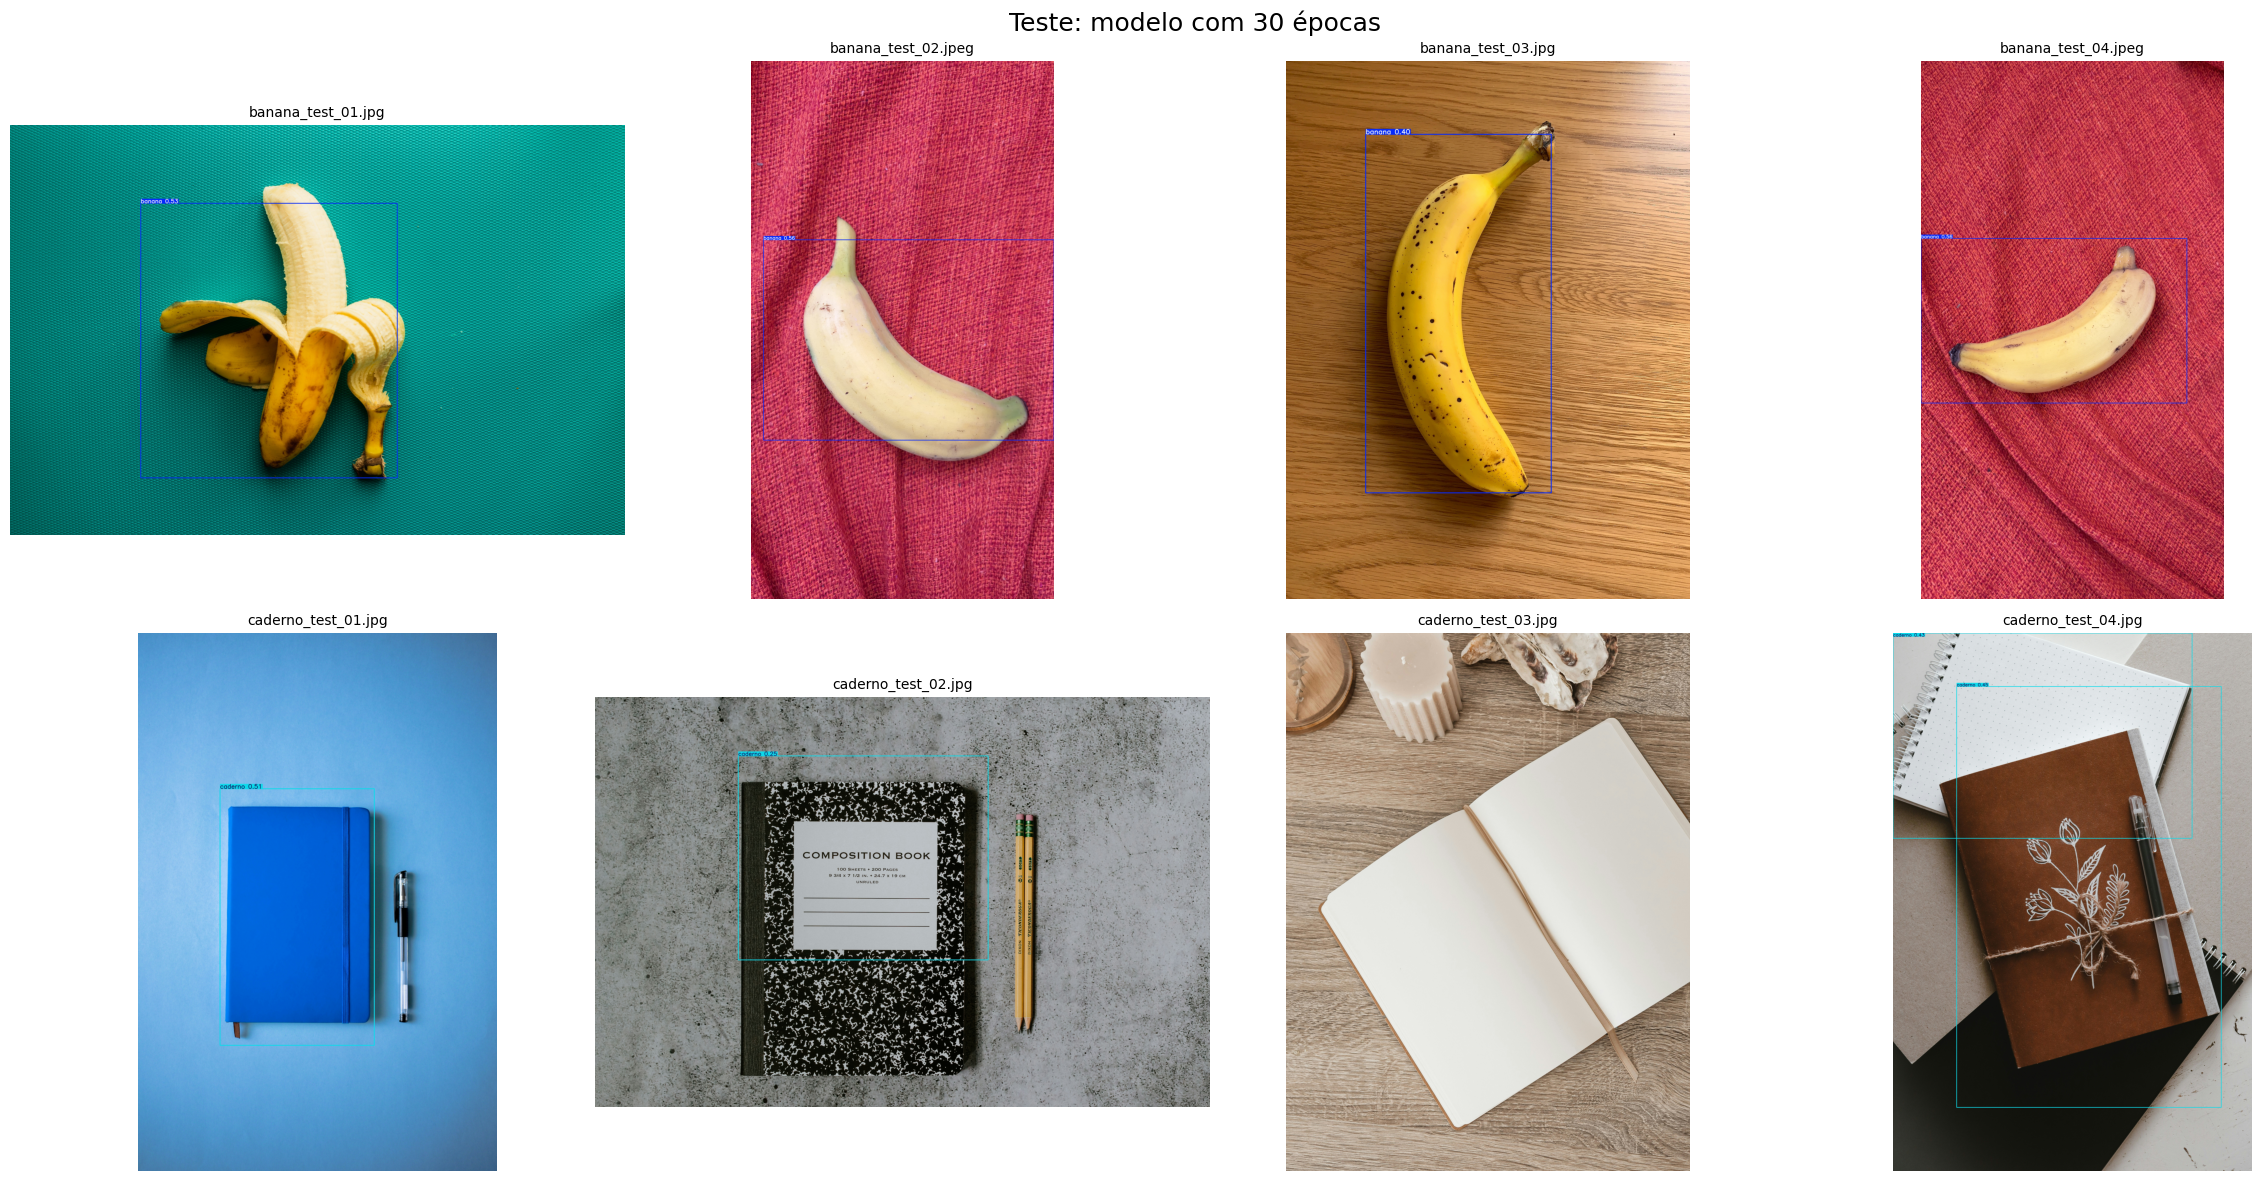

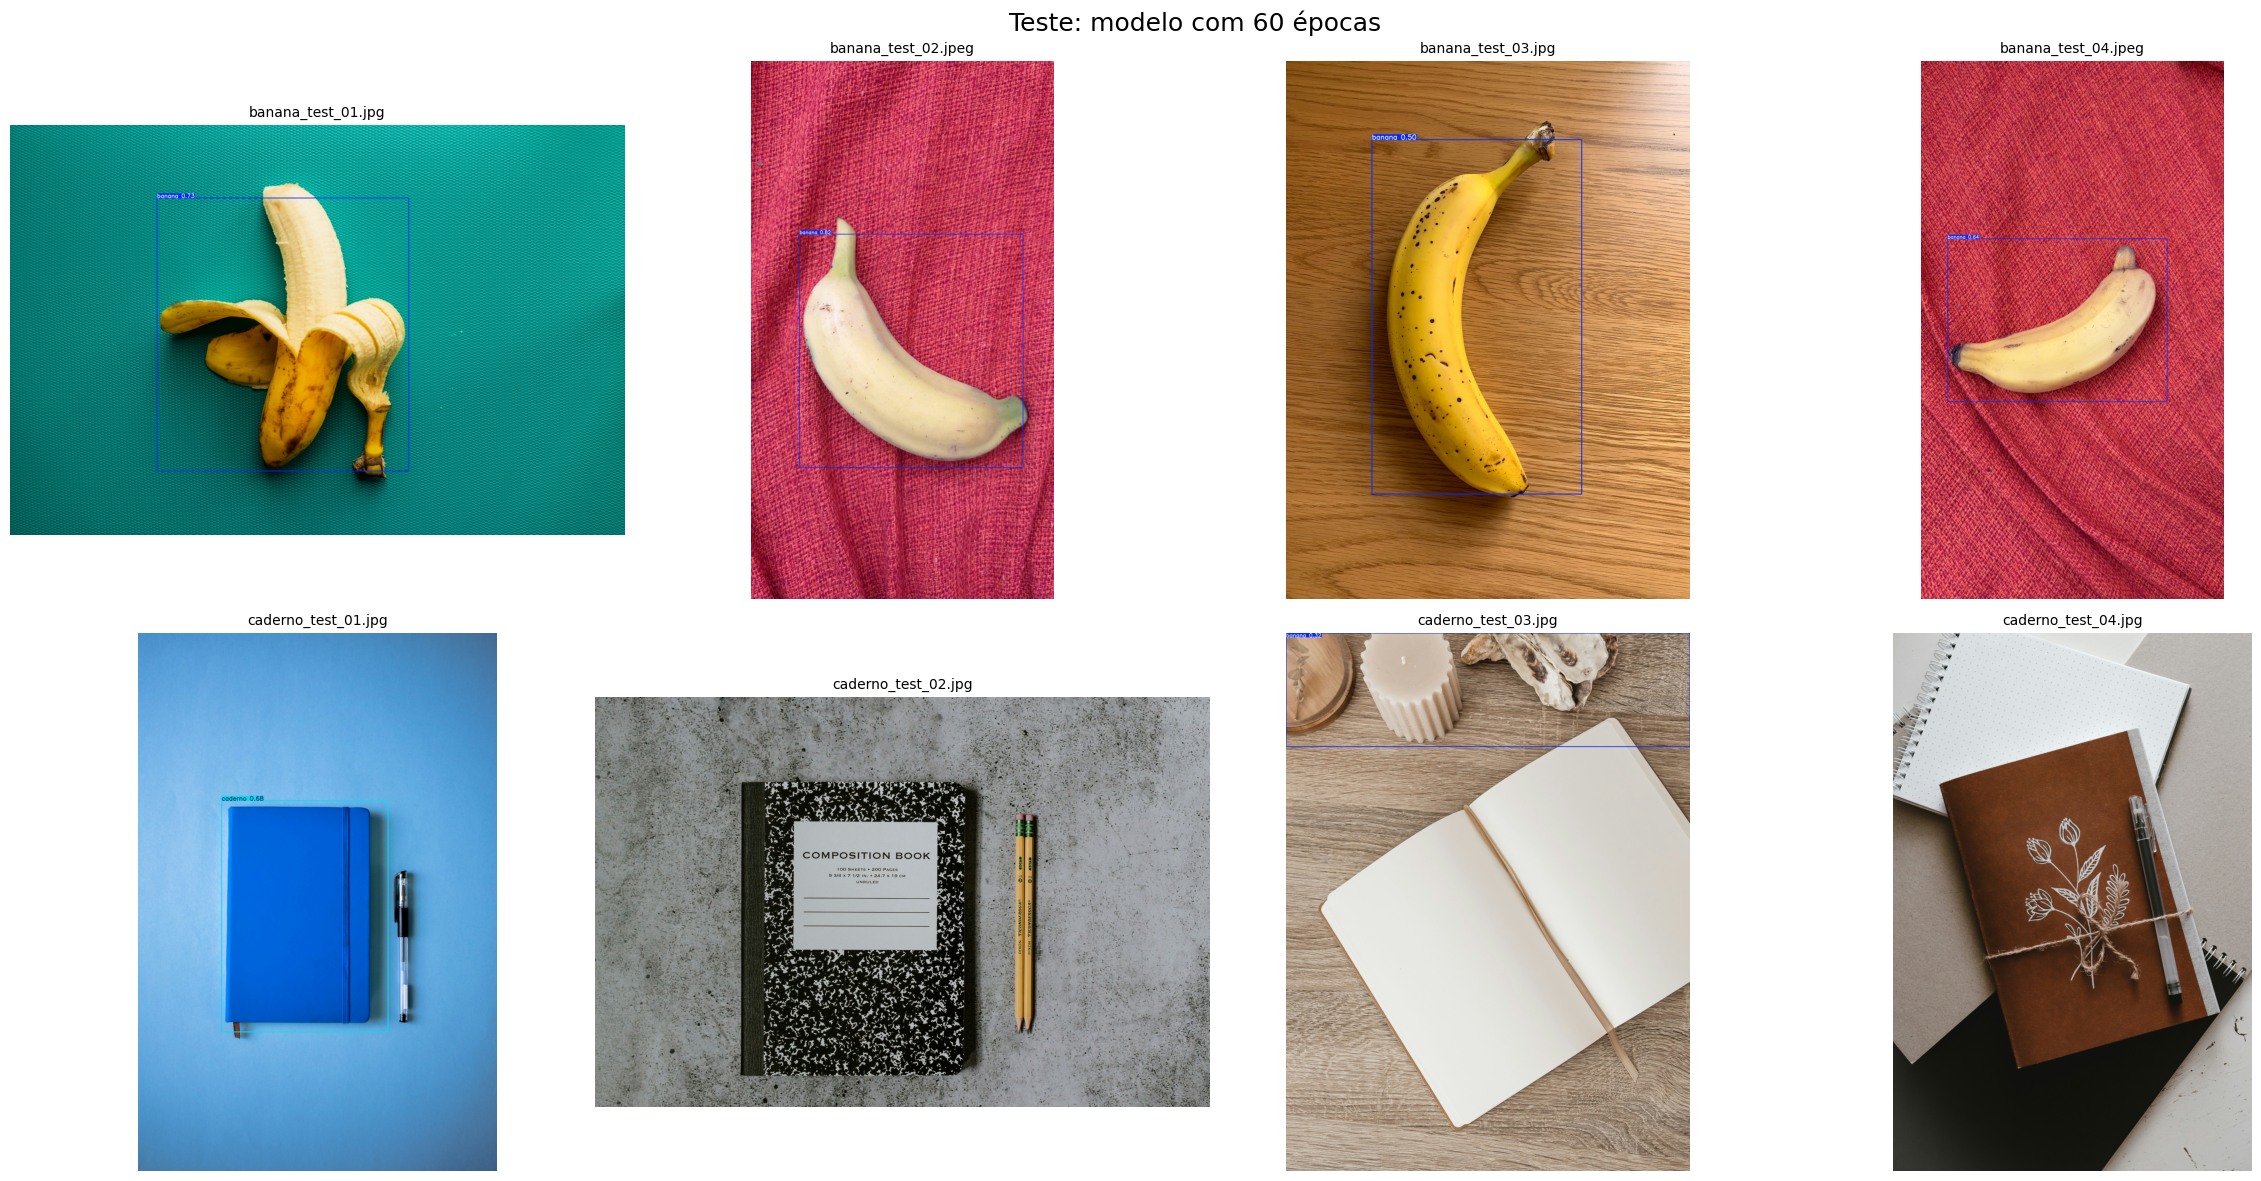

In [39]:
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def mostrar(pasta, titulo):
    """Exibe em grade as imagens processadas de uma pasta de detecção."""
    exts = ('*.jpg', '*.jpeg', '*.png')  # inclui .jpeg
    arquivos = sorted(f for e in exts for f in glob.glob(f'runs/detect/{pasta}/{e}'))
    fig, eixos = plt.subplots(2, 4, figsize=(24, 12))
    fig.suptitle(titulo, fontsize=18)
    for ax in eixos.flat:
        ax.axis('off')  # esconde eixos vazios
    for ax, arq in zip(eixos.flat, arquivos):
        ax.imshow(mpimg.imread(arq))
        ax.set_title(os.path.basename(arq), fontsize=10)
    plt.tight_layout()
    plt.show()

mostrar('detect_30ep', 'Teste: modelo com 30 épocas')
mostrar('detect_60ep', 'Teste: modelo com 60 épocas')

> Os resultados das detecções ficam em `runs/detect/detect_30ep` e `runs/detect/detect_60ep`. Usei `--name` para dar nomes descritivos às pastas, em vez do `expX` padrão do YOLOv5.

## Etapa 7: Comparação das simulações (30 vs 60 épocas)

In [40]:
import pandas as pd

# Tabela resumo: métricas de validação e teste + tempo de treino
linhas = []
for ep, tempo in ((30, tempo_30), (60, tempo_60)):
    for etapa in ('val', 'test'):
        m = resultados.get((ep, etapa), {})
        linhas.append({'Épocas': ep, 'Etapa': etapa, **m, 'Tempo treino (min)': round(tempo/60, 1)})
tabela = pd.DataFrame(linhas)
display(tabela.round(3))

,Épocas,Etapa,Precisão,Recall,mAP@0.5,mAP@0.5:0.95,Tempo treino (min)
0,30,val,1.000,0.869,0.995,0.661,2.4
1,30,test,0.896,0.998,0.945,0.421,2.4
2,60,val,0.949,1.000,0.995,0.703,3.1
3,60,test,0.780,0.875,0.829,0.486,3.1


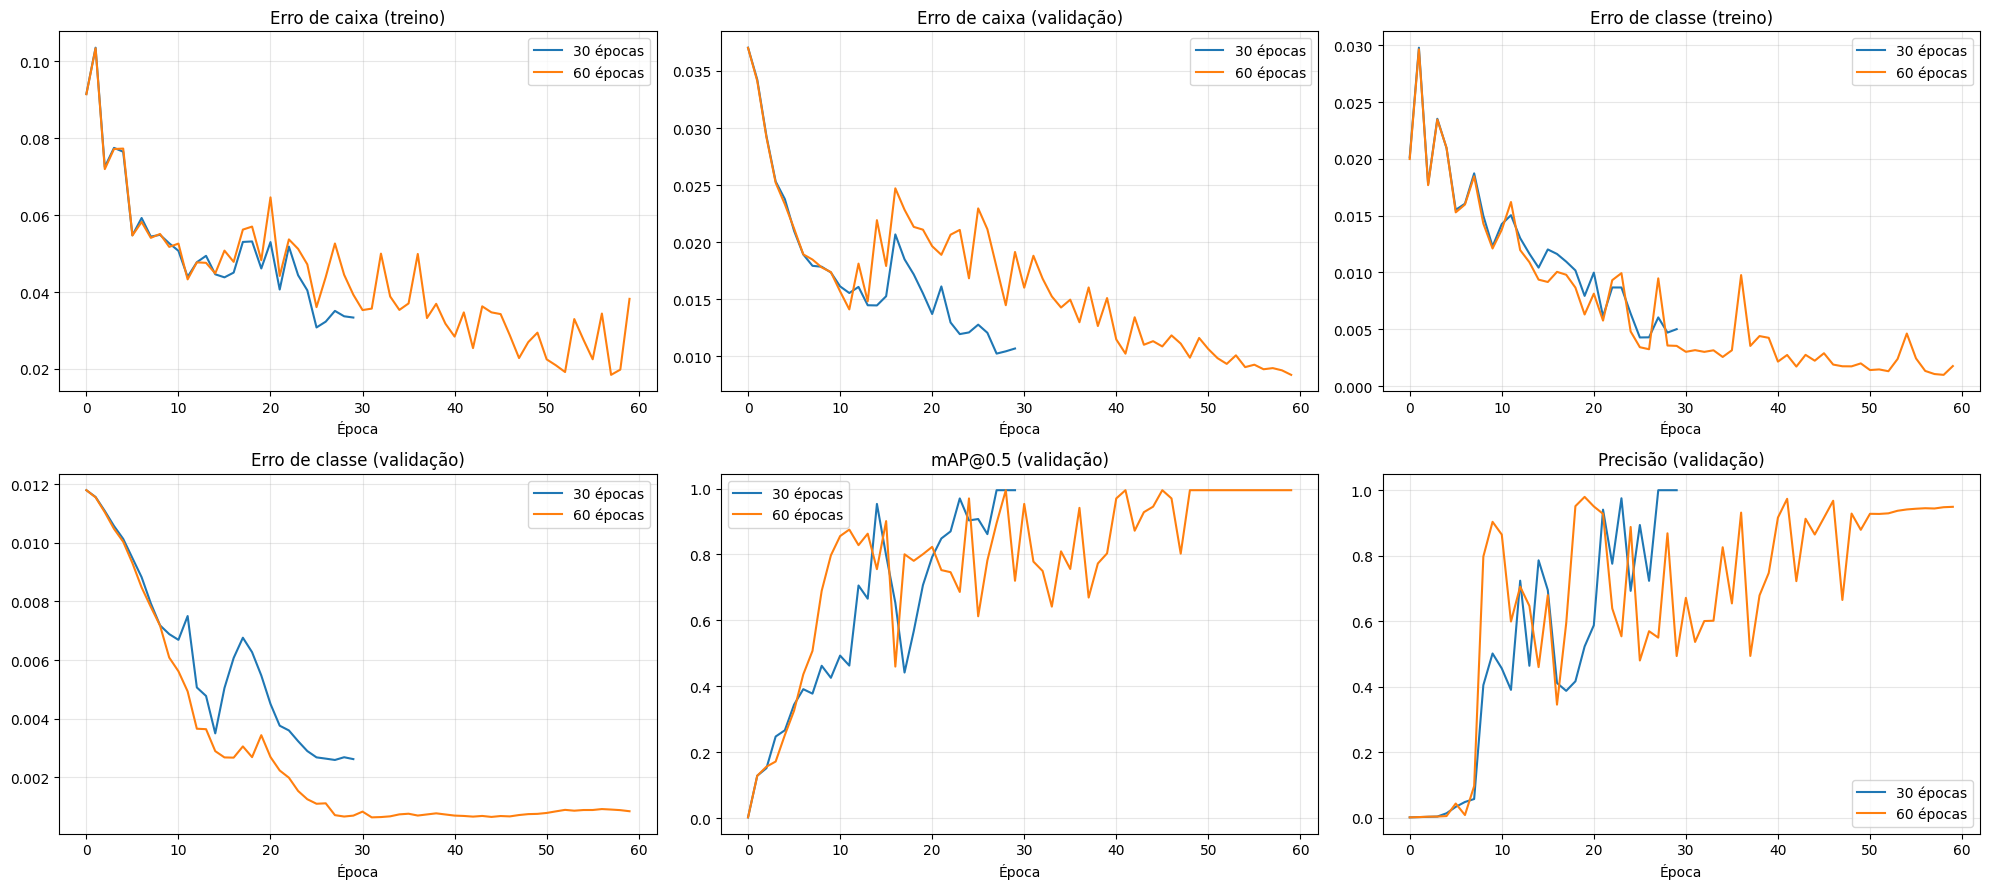

In [41]:
# Curvas de erro (loss) e métricas ao longo das épocas, para os dois treinos
fig, eixos = plt.subplots(2, 3, figsize=(20, 9))
cores = {30: 'tab:blue', 60: 'tab:orange'}

for ep in (30, 60):
    df = pd.read_csv(f'runs/train/banana_caderno_{ep}ep/results.csv')
    df.columns = df.columns.str.strip()  # remove espaços dos nomes das colunas
    graficos = [
        ('train/box_loss', 'Erro de caixa (treino)'),
        ('val/box_loss',   'Erro de caixa (validação)'),
        ('train/cls_loss', 'Erro de classe (treino)'),
        ('val/cls_loss',   'Erro de classe (validação)'),
        ('metrics/mAP_0.5', 'mAP@0.5 (validação)'),
        ('metrics/precision', 'Precisão (validação)'),
    ]
    for ax, (col, titulo) in zip(eixos.flat, graficos):
        ax.plot(df['epoch'], df[col], label=f'{ep} épocas', color=cores[ep])
        ax.set_title(titulo)
        ax.set_xlabel('Época')
        ax.legend()
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Etapa 8: Conclusões

### Resultados encontrados

| Épocas | Etapa | Precisão | Recall | mAP@0.5 | mAP@0.5:0.95 | Tempo de treino |
|---|---|---|---|---|---|---|
| 30 | validação | 1,000 | 0,869 | 0,995 | 0,661 | 2,4 min |
| 30 | teste | 0,896 | 0,998 | 0,945 | 0,421 | 2,4 min |
| 60 | validação | 0,949 | 1,000 | 0,995 | 0,703 | 3,1 min |
| 60 | teste | 0,780 | 0,875 | 0,829 | 0,486 | 3,1 min |

- **Validação:** os dois modelos chegaram a mAP@0.5 de 0,995. O de 60 épocas teve recall maior (1,000 contra 0,869) e mAP@0.5:0.95 maior (0,703 contra 0,661), enquanto o de 30 épocas teve precisão maior (1,000 contra 0,949). As diferenças são pequenas e devem ser lidas com cautela: a validação tem só 8 imagens (4 objetos por classe) e foi usada pelo próprio YOLO para escolher o melhor peso (`best.pt`), então esses números são otimistas.

- **Teste:** o desempenho caiu nos dois modelos em relação à validação, e aqui o modelo de **30 épocas foi melhor** na maioria das métricas: mAP@0.5 de 0,945 contra 0,829, recall de 0,998 contra 0,875 e precisão de 0,896 contra 0,780. A exceção foi o mAP@0.5:0.95, maior com 60 épocas (0,486 contra 0,421), puxado pelas bananas, em que as caixas ficaram mais justas (0,628 contra 0,444). Por classe, as **bananas** foram bem nos dois (mAP@0.5 de 0,995 e recall próximo de 1). Os **cadernos** são o ponto fraco: com 30 épocas, mAP@0.5 de 0,895 e precisão de 0,792; com 60 épocas, mAP@0.5 de 0,663 e recall de 0,750.
  - Nas imagens de teste (confiança mínima de 0,25), os dois modelos detectaram as **4 bananas**. Com **30 épocas**, os cadernos azul, composition book e marrom foram detectados (no composition book a caixa cobriu só a parte superior), e o caderno aberto sobre a madeira não foi detectado (falso negativo). Com **60 épocas**, só o caderno azul foi detectado corretamente: o composition book e o marrom ficaram sem caixa, e na foto do caderno aberto apareceu uma caixa indevida na região da vela e das ostras, em vez de no caderno.

- **Erro (loss):** nos dois treinos o erro de validação (caixa e classe) caiu ao longo das épocas e não voltou a subir no final, então as curvas **não mostram overfitting clássico**. O treino de 60 épocas terminou com erro menor (classe em torno de 0,0008 contra 0,0026, e caixa em torno de 0,0085 contra 0,0105) e o mAP@0.5 de validação oscilou bastante até a época ~45, estabilizando em 1,0 depois. Mesmo assim, o erro menor não se traduziu em melhor resultado no teste: a distância entre a validação (quase perfeita) e o teste indica que o modelo generaliza menos do que a validação sugere, o que é esperado com um dataset tão pequeno.

- **Desempenho:** o treino de 60 épocas levou 3,1 min, contra 2,4 min das 30 épocas (cerca de 0,7 min a mais, ou 29%, na GPU T4). Nesse dataset, o tempo extra **não trouxe ganho claro no teste**: o modelo de 30 épocas foi igual ou melhor na maioria das métricas. Como o teste tem apenas 4 objetos por classe, um único acerto ou erro muda o recall em 25 pontos, então o resultado indica que 60 épocas não foi melhor, mas não prova que 30 é sempre superior.

### Análise das detecções no teste
- **Bananas (4 de 4 nos dois modelos):** a banana descascada, a madura sobre madeira e as duas sobre o tecido vermelho foram localizadas, com confiança moderada (≈0,4 a 0,7).
- **Cadernos:** o caderno azul foi detectado pelos dois modelos. O composition book e o caderno marrom foram detectados com 30 épocas, mas não com 60. O caderno aberto sobre madeira não foi reconhecido, e o modelo de 60 épocas desenhou uma caixa na região da vela e das ostras.
- **Leitura para o cliente:** o sistema acerta bem objetos de forma bem definida e tem mais dificuldade com cadernos de aparência menos comum, o que reforça a necessidade de ampliar o dataset.

### Pontos fortes
- Classes visualmente muito distintas, o que facilita o aprendizado.
- **Transfer learning:** o treino partiu de pesos pré-treinados no COCO (um grande dataset público com ~80 categorias de objetos comuns), o que permitiu bons resultados com apenas 64 imagens de treino.
- Dataset com variedade de fundos, iluminação e estados dos objetos.

### Limitações
- **Dataset pequeno** (64 imagens de treino): métricas de validação e teste com apenas 8 imagens cada oscilam bastante, então um único erro muda muito os números.
- **Fotos próprias concentradas no treino:** validação e teste usam só imagens do Unsplash, mais "limpas" que fotos do dia a dia.
- **Séries de fotos parecidas** (mesmo cenário e objeto) podem inflar o desempenho no treino.
- Apenas duas classes, sem imagens com banana e caderno juntos e sem objetos parecidos (ex.: livro, outras frutas) para testar falsos positivos.

### Próximos passos
Ampliar o dataset, incluir imagens com os dois objetos juntos e com "distratores", e testar modelos maiores (YOLOv5m).

### Recomendação ao cliente
O sistema demonstra potencial: com apenas 64 imagens de treino, o YOLOv5 aprendeu a localizar bananas com confiabilidade (as 4 bananas de teste foram detectadas pelos dois modelos) e obteve mAP@0.5 de 0,945 no teste com 30 épocas. Os cadernos, porém, foram o ponto fraco, com falhas em objetos de aparência menos comum (como um caderno aberto sobre madeira), e treinar por mais tempo (60 épocas) não melhorou o resultado, o que indica que o limite está na quantidade e na variedade dos dados, e não no tempo de treino. Para uso real, recomendamos ampliar o banco de imagens (centenas por classe), incluir mais cenários, ângulos e iluminação, adicionar objetos parecidos para medir falsos positivos, testar modelos maiores (como o YOLOv5m) e validar com imagens do ambiente real do cliente.

## Etapa 9: Salvar os resultados no Drive
Copiamos a pasta `runs` (pesos, gráficos e imagens processadas) para o Drive, para não perder o trabalho quando o Colab desconectar.

In [42]:
# Copia os resultados para o Drive
destino = '/content/drive/MyDrive/FarmTech_YOLO/resultados_runs'
if os.path.exists(destino):
    shutil.rmtree(destino)
shutil.copytree('/content/yolov5/runs', destino)
print('Resultados salvos em', destino)

Resultados salvos em /content/drive/MyDrive/FarmTech_YOLO/resultados_runs
